# Exercise 8 — PyTorch

Last week your network ended in PyTorch as four raw tensors with autograd.
Today PyTorch also batches the data, holds the network as one object,
updates it and reads the images. First we rebuild last week's network one
PyTorch piece at a time — you run and read the cells together with the
teacher. Then you train a leaf classifier on the leaves your group
photographs at the start of the lab and let an AI agent put it on a web page
for your phone, then you write a whole pipeline of your own, and finally you
make the classifier as good as you can.

## When to use AI agents

- **Task 1: no agent needed.** Everything is written: run the cells together with the teacher and read them.
- **Task 2: run the demonstration, then use your coding agent.** Run the cells together with the teacher; the agent writes and publishes the phone page, you check it and write `REVIEW.md` yourself.
- **Task 3: work without AI agents.** Write your own `Dataset`, `DataLoader`, network and training loop; look at Tasks 1 and 2 whenever you are stuck.
- **Task 4: use your coding agent.** It writes the improvements, you decide what to try, judge the results and write the report yourself.

| Task | Your output |
| --- | --- |
| 1. PyTorch step by step | Last week's network rebuilt piece by piece — batches, `nn.Module`, loss and optimizer, `Dataset` and `DataLoader`, the GPU, evaluation and saving; nothing to write, run and read |
| 2. A leaf classifier on your phone | The demo network trained, exported and running on a public GitHub Pages page — the compulsory hand-in |
| 3. Your own pipeline | Your own `Dataset`, `DataLoader`, network and training loop, then augmentation and batch normalization measured on validation |
| 4. A better classifier | As many improvements as you can, each measured against a baseline, and a short report `REPORT.md` — compulsory hand-in too |

**Write the code yourself.** Where your code goes, the cell says
`# TODO: your code here`, sometimes followed by placeholder lines marked
`# PLACEHOLDER: replace` that only keep the notebook running — replace them
with your own code. Start the page of Task 2 and the report of Task 4 in class and finish them
at home, within **48 hours after your lab**.

<p style="color: #c00000;"><strong>! Compulsory hand-in: complete and submit Task 2 and the report of Task 4 within 48 hours after your lab. Attendance will not be credited unless you complete this requirement.</strong></p>

In [1]:
%matplotlib inline
import copy
import json
import os
import sys
import time
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split
from torchvision import datasets, models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.14.1+cu130 | device: cuda


## Task 1 — PyTorch step by step (run and read together)

Last week your two-layer network on the sine data ended as four raw tensors
with autograd. Here we rebuild that same network one PyTorch piece at a time:
**batches**, **`nn.Module`**, a **loss function and an optimizer**,
**`Dataset` and `DataLoader`**, the **GPU**, and finally **evaluation and
saving**. Every step has the same shape: first the *principle* on a few lines
you can check, then the *training* again, now with the new piece in it.
Everything is written — run the cells together with the teacher and read
them. At the end you have exactly the training loop that Task 2 runs on the
leaf photographs.

For 1f switch Colab to a GPU **before you run the first cell** (*Runtime →
Change runtime type → T4 GPU*; switching later restarts the notebook).
Everything runs on the CPU too.

### 1a. Where the seventh lab ended

The same 150 noisy samples of $\sin x$ with outliers, the same 128 hidden ReLU
neurons, the same starting weights and the loss $L = \tfrac12 (\hat y - y)^2$.
The loop below is the solution of last week's Task 5: one sample at a time,
the gradients from `backward()`, the update written by hand inside
`torch.no_grad()`.

In [2]:
np.random.seed(1)
X = 5 * np.random.rand(150)
Y = np.sin(X).ravel()
Y[::10] += 3 * (0.5 - np.random.rand(15))
Y = Y + 0.1 * np.random.randn(150)

m = 128                                        # hidden neurons
gen = np.random.default_rng(0)
W1_start = gen.normal(0.0, 0.1, (m, 1))
b1_start = gen.normal(0.0, 0.1, (m, 1))
W2_start = gen.normal(0.0, 0.1, (1, m))
b2_start = gen.normal(0.0, 0.1, (1, 1))

In [3]:
W1 = torch.tensor(W1_start, requires_grad=True)
b1 = torch.tensor(b1_start, requires_grad=True)
W2 = torch.tensor(W2_start, requires_grad=True)
b2 = torch.tensor(b2_start, requires_grad=True)
eta = 0.01
n_epochs = 100
rng = np.random.default_rng(0)
curve_0 = []

start = time.perf_counter()
for epoch in range(n_epochs):
    epoch_losses = []
    for i in rng.permutation(len(X)):
        h0 = torch.tensor(X[i].reshape(1, 1))
        y = torch.tensor(Y[i].reshape(1, 1))
        y_hat = W2 @ torch.relu(W1 @ h0 + b1) + b2
        L = torch.sum(0.5 * (y_hat - y) ** 2)
        epoch_losses.append(L.item())
        L.backward()
        with torch.no_grad():
            for p in [W1, b1, W2, b2]:
                p -= eta * p.grad
                p.grad.zero_()
    curve_0.append(np.mean(epoch_losses))
time_0 = time.perf_counter() - start
print(f"1a: final mean loss {curve_0[-1]:.4f}, {time_0:.1f} s, "
      f"{n_epochs * len(X)} updates")

1a: final mean loss 0.0569, 6.3 s, 15000 updates


### 1b. Batches: many samples in one pass

**The principle.** A Python loop over single samples is slow, and one sample
gives a noisy gradient. Instead we push a **batch** of $B$ samples through the
network at once. PyTorch puts the **samples in the rows**: the input has the
shape $(B, \text{features})$, here $(B, 1)$. A layer with the weight matrix
$W$ of shape $(\text{out}, \text{in})$ — the same shape as last week — is then

$$A = X_B W^T + \mathbf b^T,$$

one row per sample; the bias, now a plain vector of length *out*, is
broadcast over the rows. The loss of a batch is the **mean** of the losses of
its samples, and because the derivative of a mean is the mean of the
derivatives, the gradient of the batch loss is the mean of the per-sample
gradients. The cell checks this on the first five samples.

In [4]:
X_t = torch.tensor(X).reshape(-1, 1)           # (150, 1): one sample per row
Y_t = torch.tensor(Y).reshape(-1, 1)
W1 = torch.tensor(W1_start, requires_grad=True)            # (128, 1)
b1 = torch.tensor(b1_start.ravel(), requires_grad=True)    # (128,)
W2 = torch.tensor(W2_start, requires_grad=True)            # (1, 128)
b2 = torch.tensor(b2_start.ravel(), requires_grad=True)    # (1,)


def forward(x):
    return torch.relu(x @ W1.T + b1) @ W2.T + b2


# the gradient of W2, sample by sample, then averaged
per_sample = []
for i in range(5):
    L = 0.5 * (forward(X_t[i:i + 1]) - Y_t[i:i + 1]) ** 2
    L.sum().backward()
    per_sample.append(W2.grad.clone())
    W2.grad.zero_()

# the same five samples as one batch with the mean loss
L = torch.mean(0.5 * (forward(X_t[:5]) - Y_t[:5]) ** 2)
L.backward()
print("output of the batch:", forward(X_t[:5]).shape)
print("largest difference, mean of per-sample gradients vs batch gradient:",
      f"{(torch.stack(per_sample).mean(dim=0) - W2.grad).abs().max().item():.1e}")

output of the batch: torch.Size([5, 1])
largest difference, mean of per-sample gradients vs batch gradient: 1.1e-16


**The training.** The loop over samples becomes a loop over batches of
$B = 10$ samples: the shuffled order is cut into slices, each slice is one
update. An epoch now has 15 updates instead of 150, each with a less noisy
gradient, so the learning rate can be larger ($\eta = 0.1$).

1b: final mean loss 0.0530, 0.8 s (1a: 0.0569, 6.3 s)


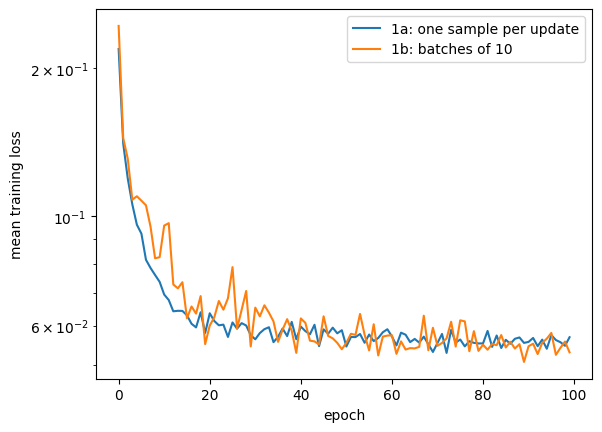

In [5]:
W1 = torch.tensor(W1_start, requires_grad=True)
b1 = torch.tensor(b1_start.ravel(), requires_grad=True)
W2 = torch.tensor(W2_start, requires_grad=True)
b2 = torch.tensor(b2_start.ravel(), requires_grad=True)
batch_size = 10
eta = 0.1
rng = np.random.default_rng(0)
curve_1 = []

start = time.perf_counter()
for epoch in range(n_epochs): #In each epoch different batches
    order = rng.permutation(len(X))
    loss_sum = 0.0
    for first in range(0, len(X), batch_size):
        batch = order[first:first + batch_size]
        L = torch.mean(0.5 * (forward(X_t[batch]) - Y_t[batch]) ** 2)
        loss_sum += L.item() * len(batch)
        L.backward()
        with torch.no_grad():
            for p in [W1, b1, W2, b2]:
                p -= eta * p.grad
                p.grad.zero_()
    curve_1.append(loss_sum / len(X))
time_1 = time.perf_counter() - start
print(f"1b: final mean loss {curve_1[-1]:.4f}, {time_1:.1f} s "
      f"(1a: {curve_0[-1]:.4f}, {time_0:.1f} s)")

plt.plot(curve_0, label="1a: one sample per update")
plt.plot(curve_1, label=f"1b: batches of {batch_size}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("mean training loss")
plt.legend()
plt.show()

**Try it:** with `batch_size = 1` and `eta = 0.01` the loop is exactly
1a again — the final loss is 0.0569. With `batch_size = 150` every update
uses all data (plain gradient descent); how many epochs does it then need?

### 1c. The network as an `nn.Module`

**The principle.** Four loose tensors do not scale to a network with fifty
layers. PyTorch keeps a network in an object:

- `nn.Parameter` is a tensor that records its gradient *and* tells the
  object that holds it: "I am a parameter".
- A class inheriting from `nn.Module` **registers** every `nn.Parameter` and
  every other module it stores as an attribute (`self.w = ...`).
  `model.parameters()` then lists all of them, also inside the sub-modules,
  and `model(x)` calls its `forward(x)`. The call `super().__init__()` comes
  first, it creates the registry.
- `nn.Linear(in, out)` is nothing more than such a module: a weight
  $(\text{out}, \text{in})$, a bias of length *out*, and `forward` computing
  $X W^T + \mathbf b^T$ — 1b's layer.

The cell writes that layer by hand and compares it with `nn.Linear`.

In [6]:
class MyLinear(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.weight = nn.Parameter(0.1 * torch.randn(n_out, n_in))
        self.bias = nn.Parameter(torch.zeros(n_out))

    def forward(self, x):
        return x @ self.weight.T + self.bias


torch.manual_seed(0)
mine = MyLinear(3, 2)
theirs = nn.Linear(3, 2)
with torch.no_grad():                           # the same numbers in both
    theirs.weight.copy_(mine.weight)
    theirs.bias.copy_(mine.bias)

for name, p in mine.named_parameters():
    print(name, tuple(p.shape), "requires_grad =", p.requires_grad)
x = torch.randn(4, 3)
print("MyLinear == nn.Linear:", torch.allclose(mine(x), theirs(x)))

weight (2, 3) requires_grad = True
bias (2,) requires_grad = True
MyLinear == nn.Linear: True


**One more thing: the number type.** NumPy computes in `float64`, PyTorch
layers are created in **`float32`** — half the memory, and what GPUs are fast
at. The data must be converted to the same type, otherwise PyTorch stops with
an error:

In [7]:
try:
    theirs(torch.tensor([[1.0, 2.0, 3.0]], dtype=torch.float64))
except RuntimeError as error:
    print("RuntimeError:", error)
print("with .float():", theirs(torch.tensor([[1.0, 2.0, 3.0]], dtype=torch.float64).float()))

RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float
with .float(): tensor([[-0.5582, -0.5796]], grad_fn=<AddmmBackward0>)


**The training.** The sine network as a module with two `nn.Linear` layers.
It starts from last week's weights (copied in, so that we can compare), the
data go to `float32`, and the update loops over `model.parameters()` — the
loop no longer needs to know what is inside the network. Apart from the
number type, this is 1b.

In [8]:
class SineNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.layer1 = nn.Linear(1, hidden)
        self.layer2 = nn.Linear(hidden, 1)

    def forward(self, x):
        return self.layer2(torch.relu(self.layer1(x)))


def start_model():
    # a SineNet with the starting weights of the seventh lab
    model = SineNet()
    with torch.no_grad():
        model.layer1.weight.copy_(torch.tensor(W1_start))
        model.layer1.bias.copy_(torch.tensor(b1_start.ravel()))
        model.layer2.weight.copy_(torch.tensor(W2_start))
        model.layer2.bias.copy_(torch.tensor(b2_start.ravel()))
    return model


model = start_model()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

SineNet(
  (layer1): Linear(in_features=1, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=1, bias=True)
)
parameters: 385


In [9]:
X_f, Y_f = X_t.float(), Y_t.float()             # float32, like the layers
model = start_model()
rng = np.random.default_rng(0)
curve_2 = []

for epoch in range(n_epochs):
    order = rng.permutation(len(X))
    loss_sum = 0.0
    for first in range(0, len(X), batch_size):
        batch = order[first:first + batch_size]
        L = torch.mean(0.5 * (model(X_f[batch]) - Y_f[batch]) ** 2)
        loss_sum += L.item() * len(batch)
        L.backward()
        with torch.no_grad():
            for p in model.parameters():
                p -= eta * p.grad #stochaic gradient descent ?
                p.grad.zero_()
    curve_2.append(loss_sum / len(X))
print(f"1c: final mean loss {curve_2[-1]:.4f}; "
      f"largest difference from 1b: {np.abs(np.array(curve_2) - curve_1).max():.1e} (float32)")

1c: final mean loss 0.0530; largest difference from 1b: 1.9e-08 (float32)


For a plain chain of layers PyTorch has a ready-made container,
`nn.Sequential(nn.Linear(1, 128), nn.ReLU(), nn.Linear(128, 1))` — the same
network without writing a class. A class is needed as soon as `forward` does
anything else than passing the output to the next layer (your
convolutional network of Task 3, a skip connection, two inputs).

### 1d. Loss function and optimizer

**The principle.** Two lines of the loop are still written by hand: the loss
and the update. PyTorch has both ready:

- `nn.MSELoss()` computes the mean of $(\hat y - y)^2$ — **without** our
  $\tfrac12$, so its value and its gradient are twice ours.
  (`nn.CrossEntropyLoss()` of Task 2 is used in the same way.)
- An **optimizer** is given the list of parameters once.
  `optimizer.step()` updates all of them from their `.grad` — for plain SGD
  exactly $p \leftarrow p - \eta \nabla_p L$, our `no_grad()` lines —
  and `optimizer.zero_grad()` clears the gradients.

The cell checks both on one batch.

In [10]:
criterion = nn.MSELoss()
model = start_model()
xb, yb = X_f[:10], Y_f[:10]
print("MSELoss:", criterion(model(xb), yb).item(),
      " 2 * our loss:", (2 * torch.mean(0.5 * (model(xb) - yb) ** 2)).item())

# one step by hand on one copy, one step of torch.optim.SGD on another
by_hand, with_opt = start_model(), start_model()
optimizer = torch.optim.SGD(with_opt.parameters(), lr=0.1)

criterion(by_hand(xb), yb).backward()
with torch.no_grad():
    for p in by_hand.parameters():
        p -= 0.1 * p.grad

optimizer.zero_grad()
criterion(with_opt(xb), yb).backward()
optimizer.step()

difference = max((p - q).abs().max().item()
                 for p, q in zip(by_hand.parameters(), with_opt.parameters()))
print(f"largest difference between the two updated networks: {difference:.1e}")

MSELoss: 1.5113818645477295  2 * our loss: 1.5113818645477295
largest difference between the two updated networks: 7.5e-09


**The training.** The loop now has the four lines that every PyTorch training
has — `zero_grad`, loss, `backward`, `step`. Because `MSELoss` has twice our
gradient, SGD with half the learning rate ($0.05$) takes exactly 1c's
steps; the recorded loss is then twice 1c's. Then we change **one line**:
the optimizer becomes **Adam** from the seventh lecture, with its own
per-parameter step size.

SGD : final MSE 0.1060
Adam: final MSE 0.0991
SGD vs 1c (MSE = 2 x our loss): largest difference 2.9e-08


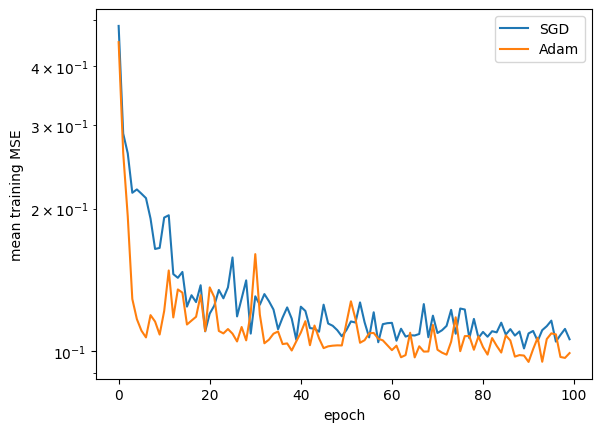

In [11]:
curves_3 = {}
for name in ["SGD", "Adam"]:
    model = start_model()
    if name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=eta / 2)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    rng = np.random.default_rng(0)
    curve = []
    for epoch in range(n_epochs):
        order = rng.permutation(len(X))
        loss_sum = 0.0
        for first in range(0, len(X), batch_size):
            batch = order[first:first + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X_f[batch]), Y_f[batch])
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(batch)
        curve.append(loss_sum / len(X))
    curves_3[name] = np.array(curve)
    print(f"{name:4s}: final MSE {curve[-1]:.4f}")

print(f"SGD vs 1c (MSE = 2 x our loss): largest difference "
      f"{np.abs(curves_3['SGD'] - 2 * np.array(curve_2)).max():.1e}")
for name, curve in curves_3.items():
    plt.plot(curve, label=name)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("mean training MSE")
plt.legend()
plt.show()

### 1e. `Dataset` and `DataLoader`

**The principle.** The shuffling and slicing of 1b is bookkeeping that
every training needs. PyTorch splits it in two:

- a **`Dataset`** knows the data: `len(dataset)` is the number of samples and
  `dataset[i]` returns sample `i` as the pair `(x, y)`. `TensorDataset` makes
  one from tensors; `ImageFolder` of Task 2 reads one from a folder
  of photographs — the loop does not see the difference;
- a **`DataLoader`** takes a `Dataset` and, in every epoch, shuffles the
  indices, takes `batch_size` samples at a time and stacks them into one
  tensor.

In [12]:
dataset = TensorDataset(X_f, Y_f)
print("len(dataset) =", len(dataset), "  dataset[0] =", dataset[0])

loader = DataLoader(dataset, batch_size=32, shuffle=True,
                    generator=torch.Generator().manual_seed(0))
print("batches in one epoch:", len(loader))
for xb, yb in loader:
    print("  batch:", tuple(xb.shape), tuple(yb.shape))

len(dataset) = 150   dataset[0] = (tensor([2.0851]), tensor([2.4009]))
batches in one epoch: 5
  batch: (32, 1) (32, 1)
  batch: (32, 1) (32, 1)
  batch: (32, 1) (32, 1)
  batch: (32, 1) (32, 1)
  batch: (22, 1) (22, 1)


150 is not divisible by 32: the last batch has the 22 samples that are left
(`drop_last=True` would throw it away).

**The training.** The two lines with `order` and `batch` disappear, the loop
runs over the loader. The shuffling now comes from PyTorch's generator instead
of NumPy's, so the curve is no longer identical to 1d's — only similar.
As in Tasks 2 and 3, the loss of an epoch is the mean of its batch losses;
with batches of equal size that is the mean over the samples.

In [13]:
torch.manual_seed(0)
model = start_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loader = DataLoader(dataset, batch_size=10, shuffle=True,
                    generator=torch.Generator().manual_seed(0))
curve_4 = []

for epoch in range(n_epochs):
    loss_sum = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()
    curve_4.append(loss_sum / len(loader))
print(f"1e: final MSE {curve_4[-1]:.4f} (1d with Adam: {curves_3['Adam'][-1]:.4f})")

1e: final MSE 0.0985 (1d with Adam: 0.0991)


### 1f. The GPU

**The principle.** A tensor lives on a **device**: in RAM (`cpu`) or in the
memory of a graphics card (`cuda`). An operation runs where its inputs are,
and all its inputs must be on the same device. `tensor.to(device)` returns a
copy on that device; `model.to(device)` moves all parameters of a module;
`.cpu()` brings a result back (`.numpy()` and plotting need it, `.item()` does
it for one number).

A GPU has thousands of simple cores: it is fast on **large** operations that
can run in parallel — a big matrix product, a convolution over a batch of
images. Every call also has a fixed cost (starting the computation on the
card, copying data there), so for tiny operations the CPU wins. GPU calls
return before the card has finished, so a fair stopwatch waits for it with
`torch.cuda.synchronize()`.

In [14]:
print("device:", device)                       # set in the first cell: the GPU if there is one


def seconds(n, dev, repeat=5):
    # the average time of one product of two n x n matrices on dev
    a, b = torch.randn(n, n, device=dev), torch.randn(n, n, device=dev)
    a @ b                                        # warm-up
    if dev.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeat):
        a @ b
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / repeat


for n in [16, 256, 2048]:
    line = f"{n:5d} x {n:<5d}  cpu {1e3 * seconds(n, torch.device('cpu')):8.3f} ms"
    if device.type == "cuda":
        line += f"   gpu {1e3 * seconds(n, device):8.3f} ms"
    print(line)

if device.type == "cuda":
    try:
        torch.ones(2, device=device) + torch.ones(2)
    except RuntimeError as error:
        print("mixing devices:", str(error).splitlines()[0])

device: cuda
   16 x 16     cpu    0.019 ms   gpu    0.053 ms
  256 x 256    cpu    0.151 ms   gpu    0.050 ms
 2048 x 2048   cpu   46.611 ms   gpu    1.206 ms
mixing devices: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!


**The training.** Three changes: the model goes to the device once, before
the optimizer is created; every batch goes there inside the loop; the
prediction for the plot comes back with `.cpu()`. On a GPU this tiny network
trains *no faster* than on the CPU, usually slower — 385 parameters and batches of ten are far
too small to keep the card busy. With the photographs and MobileNet of
Task 2 it is many times faster; the code is the same.

1f on cuda: final MSE 0.0985, 2.9 s


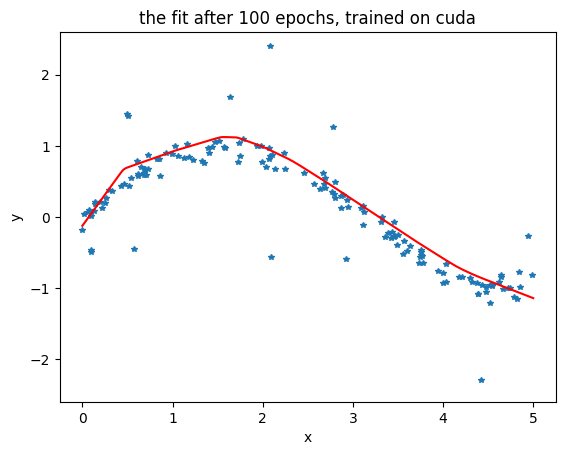

In [15]:
torch.manual_seed(0)
model = start_model().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loader = DataLoader(dataset, batch_size=10, shuffle=True,
                    generator=torch.Generator().manual_seed(0))
curve_5 = []

start = time.perf_counter()
for epoch in range(n_epochs):
    loss_sum = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()
    curve_5.append(loss_sum / len(loader))
print(f"1f on {device}: final MSE {curve_5[-1]:.4f}, {time.perf_counter() - start:.1f} s")

grid = torch.linspace(0, 5, 200).reshape(-1, 1)
with torch.no_grad():
    fit = model(grid.to(device)).cpu()
plt.plot(X, Y, "*", markersize=4)
plt.plot(grid, fit, "r-")
plt.ylim(-2.6, 2.6)
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"the fit after {n_epochs} epochs, trained on {device}")
plt.show()

### 1g. Validation, evaluation mode and saving

**The principle.** Three last pieces:

- **`model.train()` and `model.eval()`** switch layers that behave differently
  while training: dropout switches neurons off at random only in training
  mode, batch normalization uses the statistics of the batch only in training
  mode. A network without such layers ignores the switch — but the habit
  prevents a silent error once you add them. Evaluation also runs inside
  `torch.no_grad()`: nothing is recorded, less memory and time.
- **`state_dict()`** is the ordered dictionary *parameter name → tensor*: all
  the network has learned. `torch.save` writes it to a file,
  `load_state_dict` puts it into a new object of the same class. The
  dictionary holds the live tensors, which the next `optimizer.step()`
  changes, so the weights of the best epoch are kept as a `copy.deepcopy`.
- **`random_split`** divides a `Dataset` into a training and a validation
  part, so that we can see when the network stops improving on data it does
  not train on.

In [16]:
dropout = nn.Dropout(p=0.5)
ones = torch.ones(1, 8)
dropout.train()
print("train mode:", dropout(ones))   # half the values zeroed, the rest scaled by 2
dropout.eval()
print("eval mode: ", dropout(ones))   # unchanged

state = start_model().state_dict()
for name, tensor in state.items():
    print(f"{name:15s} {tuple(tensor.shape)}")

train mode: tensor([[0., 2., 0., 2., 0., 0., 0., 2.]])
eval mode:  tensor([[1., 1., 1., 1., 1., 1., 1., 1.]])
layer1.weight   (128, 1)
layer1.bias     (128,)
layer2.weight   (1, 128)
layer2.bias     (1,)


**The training — the complete loop.** 120 samples for training, 30 for
validation. Every epoch: training mode and the batch loop of 1f, then
evaluation mode and the validation loss without gradients. The weights of
the epoch with the lowest validation loss are kept, saved to a file and
loaded into a fresh `SineNet`, which must predict exactly the same.

best validation MSE 0.0337 in epoch 100
the loaded network predicts exactly the same: True


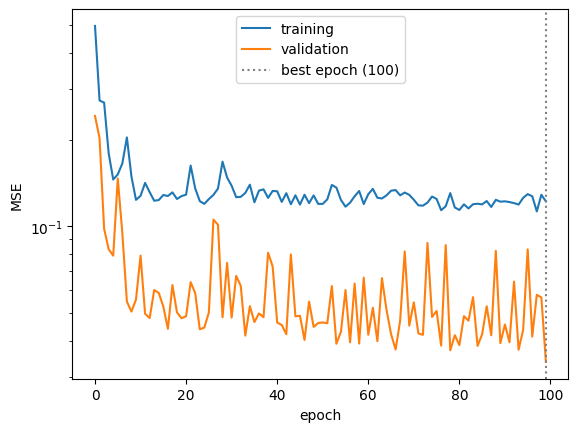

In [17]:
train_set, val_set = random_split(dataset, [120, 30], generator=torch.Generator().manual_seed(0))
train_loader = DataLoader(train_set, batch_size=10, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
val_loader = DataLoader(val_set, batch_size=30)

torch.manual_seed(0)
model = start_model().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
train_curve, val_curve = [], []
best_loss, best_state = float("inf"), None

for epoch in range(n_epochs): #Traning loop
    model.train()
    loss_sum = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()
    train_curve.append(loss_sum / len(train_loader))

    model.eval() #switching model and eval loop
    loss_sum = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss_sum += criterion(model(xb), yb).item()
    val_curve.append(loss_sum / len(val_loader))
    if val_curve[-1] < best_loss:
        best_loss, best_epoch = val_curve[-1], epoch + 1
        best_state = copy.deepcopy(model.state_dict())

print(f"best validation MSE {best_loss:.4f} in epoch {best_epoch}")
torch.save(best_state, "sine_net.pt")

loaded = SineNet().to(device)
loaded.load_state_dict(torch.load("sine_net.pt"))
loaded.eval()
model.load_state_dict(best_state)
with torch.no_grad():
    same = torch.equal(loaded(grid.to(device)), model(grid.to(device)))
print("the loaded network predicts exactly the same:", same)

plt.plot(train_curve, label="training")
plt.plot(val_curve, label="validation")
plt.axvline(best_epoch - 1, color="gray", linestyle=":", label=f"best epoch ({best_epoch})")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

Here the validation loss is still falling at the end, so the best epoch is
the last one: 385 parameters do not overfit 120 samples in 100 epochs. The
same few lines matter for the large networks of Tasks 2–4, whose
validation loss can start rising long before the last epoch.

**Try it:** add the line `n_epochs = 300` at the top of the cell — does the best epoch
stay the last one? The validation set has only 30 samples, and how many of the 15
outliers fall into it depends on the split. Change the seed of
`random_split` — how much does the best validation MSE move? Then add `nn.Dropout(0.2)` after the ReLU
in `SineNet.forward` (create it in `__init__`) and compare the two curves.

**What Task 1 built.** The loop of 1g is the loop of Task 2: only the data
and the network differ — photographs instead of sine samples, MobileNet
instead of `SineNet`, `nn.CrossEntropyLoss` instead of `nn.MSELoss`. Every
line came from one step:

* **Batches** (1b): samples in the rows, the loss is the mean over the
  batch, its gradient the mean of the per-sample gradients.
* **`nn.Module`** (1c): parameters registered as attributes after
  `super().__init__()`, `model.parameters()` lists them, `model(x)` calls
  `forward`; `nn.Linear` computes $X W^T + \mathbf b^T$; layers are `float32`.
* **Loss and optimizer** (1d): `zero_grad()`, `loss = criterion(...)`,
  `backward()`, `step()`; changing SGD to Adam is one line.
* **`Dataset` / `DataLoader`** (1e): the data say `len` and `[i]`, the
  loader shuffles and batches.
* **Device** (1f): model and batches `.to(device)`, results `.cpu()`; the
  GPU pays off only for large operations.
* **Evaluation and saving** (1g): `train()` / `eval()`, `no_grad()` for
  validation, `state_dict()` for the best epoch and the file.

## Task 2 — A leaf classifier on your phone (demonstration + agent, compulsory)

In the first lab we classified leaves from two numbers measured with a ruler.
Now the input is the photograph itself: $96 \times 96 \times 3 = 27\,648$
numbers, and nobody measures anything. Run the cells together with the
teacher; in Task 3 you write a pipeline like this yourself, in Task 4 you
improve it.

### 2a. The data

The photographs your group took at the start of the lab: four species, one
folder per species on Drive. The teacher has packed them into one zip — every
photo centre-cropped and resized to $96 \times 96$ pixels and split into
training and validation so that **a student's photos of one species all stay
on the same side**.
The validation therefore measures what matters: leaves the network has
never seen, photographed by other students with other phones. The folder
layout is the convention every image library understands — one folder
per class:

```
data/leaves/train/apple/…  data/leaves/train/cherry/…  data/leaves/train/chestnut/…  data/leaves/train/maple/…
data/leaves/val/apple/…    data/leaves/val/cherry/…    data/leaves/val/chestnut/…    data/leaves/val/maple/…
```

Paste the **shared ZIP file link from the teacher's Google Drive** into
`GROUP_ZIP`. Use the file link (for example,
`https://drive.google.com/file/d/FILE_ID/view?usp=sharing`), not an upload-folder
link. The ZIP must be shared as **Anyone with the link — Viewer**.
The cell downloads that ZIP and extracts it into `data/leaves`; it does not
use a GitHub dataset. Without the link, wait for the teacher.
If you switch to another ZIP after a run, delete `data/leaves` first and
run this cell again.

In [18]:
%pip install -q "gdown>=6.0"
GROUP_ZIP = "https://drive.google.com/file/d/1UDLwa3gJL9nWEiZ-6WbrbMk-yQvExgv_/view?usp=sharing"   # Paste the shared ZIP file link from your teacher's Google Drive.

from pathlib import Path
from urllib.parse import urlparse
import gdown

GROUP_ZIP = GROUP_ZIP.strip()
if not GROUP_ZIP:
    raise ValueError("Paste the teacher's shared Google Drive ZIP file link into GROUP_ZIP first.")
link = urlparse(GROUP_ZIP)
if link.hostname != "drive.google.com" or "/folders/" in link.path:
    raise ValueError("GROUP_ZIP must be a Google Drive file link, not a folder link.")

os.makedirs("data", exist_ok=True)
source_file = Path("data/leaves/.group_zip_url")
if Path("data/leaves").exists():
    if not source_file.exists() or source_file.read_text().strip() != GROUP_ZIP:
        raise ValueError("The cached data came from another or unknown ZIP. Delete data/leaves and rerun this cell.")
else:
    downloaded = gdown.download(url=GROUP_ZIP, output="data/leaves.zip", quiet=False)
    if not downloaded or not zipfile.is_zipfile("data/leaves.zip"):
        raise RuntimeError("Could not download a ZIP. Ask the teacher to enable 'Anyone with the link — Viewer'.")
    with zipfile.ZipFile("data/leaves.zip") as archive:
        names = archive.namelist()
        if not all(any(name.startswith(f"leaves/{split}/") for name in names) for split in ["train", "val"]):
            raise ValueError("The ZIP must contain leaves/train and leaves/val folders.")
        archive.extractall("data")
    source_file.write_text(GROUP_ZIP)
print("Group dataset ready in data/leaves.")

Downloading...
From: https://drive.google.com/uc?id=1UDLwa3gJL9nWEiZ-6WbrbMk-yQvExgv_
To: /content/data/leaves.zip
100%|██████████| 352k/352k [00:00<00:00, 109MB/s]

Group dataset ready in data/leaves.


In [21]:
import zipfile
import os

# Let's fix the error by re-extracting the dataset that was accidentally deleted earlier
if os.path.exists('data/leaves.zip'):
    with zipfile.ZipFile('data/leaves.zip', 'r') as zip_ref:
        zip_ref.extractall('data')
    print('Successfully restored data/leaves from zip! You can now run the cells below.')
else:
    print('Zip file not found. Please rerun the cell above that downloads GROUP_ZIP.')

Successfully restored data/leaves from zip! You can now run the cells below.


`ImageFolder` reads such a folder — a ready-made `Dataset`, like
`TensorDataset` in 1e: the subfolder names become the classes,
every file a sample. The `transform` turns a PIL image into a tensor —
`ToTensor` divides by 255 and moves the channels first, `(H, W, 3)` becomes
`(3, H, W)` — and `Normalize` standardizes every channel with the usual
ImageNet mean and standard deviation. A `DataLoader` then shuffles the
samples and stacks them into batches of shape `(batch, 3, 96, 96)`.

In [22]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = datasets.ImageFolder("data/leaves/train", transform=transform)
val_ds = datasets.ImageFolder("data/leaves/val", transform=transform)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)

images, labels = next(iter(train_loader))
print(train_ds.classes, "| train", len(train_ds), "| val", len(val_ds))
print("one batch:", tuple(images.shape), "labels", labels[:8].tolist())

['apple', 'cherry', 'chestnut', 'maple'] | train 107 | val 29
one batch: (32, 3, 96, 96) labels [0, 1, 3, 1, 3, 0, 0, 0]


### 2b. The network: a pretrained MobileNet

We do not start from random weights. `mobilenet_v3_small` is a small
convolutional network made for phones and already trained on ImageNet
(1.2 million photographs, 1000 classes): its layers have learned edges,
textures and shapes useful in any photograph. We replace its last layer
(1000 outputs) with a new one with 4 outputs and train the whole network a
little further on our leaves — *transfer learning*, a topic of the tenth
lecture. A small network trained from scratch on a few dozen photographs per species
learns these photographs rather than leaves: in our tests on last years'
photos it recognised only about 56 % of the leaves from another photo
session, the pretrained one about 75 % — and the phone camera always shows
a new session.

The output has **no softmax**: `nn.CrossEntropyLoss` applies it itself, so
the network returns raw scores (*logits*).

In [23]:
torch.manual_seed(0)
model = models.mobilenet_v3_small(weights="DEFAULT")
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 4)
model = model.to(device)
print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 122MB/s]

Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=4, bias=True)
)


### 2c. Training

The loop is the one of 1g — training mode, the batch loop with `zero_grad()`,
loss, `backward()`, `step()`, then evaluation mode and the validation inside
`torch.no_grad()`. Only the data and the network differ: batches of
photographs moved to the device, MobileNet instead of `SineNet`, and
`nn.CrossEntropyLoss` instead of `nn.MSELoss`, because the outputs are
classes; Adam needs no tuning of the learning rate here. After every epoch
we count the correct validation predictions. MobileNet contains batch
normalization and dropout, so `model.train()` and `model.eval()` now really
change what the network computes.

In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(15):
    model.train()
    loss_sum = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()

    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(dim=1) == labels).sum().item()
    print(f"epoch {epoch + 1:2d}  training loss {loss_sum / len(train_loader):.4f}  validation accuracy {correct / len(val_ds):.3f}")

epoch  1  training loss 0.9883  validation accuracy 0.586
epoch  2  training loss 0.2222  validation accuracy 0.690
epoch  3  training loss 0.0821  validation accuracy 0.655
epoch  4  training loss 0.0354  validation accuracy 0.690
epoch  5  training loss 0.0111  validation accuracy 0.690
epoch  6  training loss 0.0220  validation accuracy 0.655
epoch  7  training loss 0.0024  validation accuracy 0.655
epoch  8  training loss 0.0010  validation accuracy 0.655
epoch  9  training loss 0.0020  validation accuracy 0.690
epoch 10  training loss 0.0014  validation accuracy 0.690
epoch 11  training loss 0.0011  validation accuracy 0.655
epoch 12  training loss 0.0004  validation accuracy 0.690
epoch 13  training loss 0.0005  validation accuracy 0.759
epoch 14  training loss 0.0118  validation accuracy 0.655
epoch 15  training loss 0.0001  validation accuracy 0.655


### 2d. Where the mistakes are

One number is never enough: the confusion matrix from the second lab says
*which* species get mixed up.

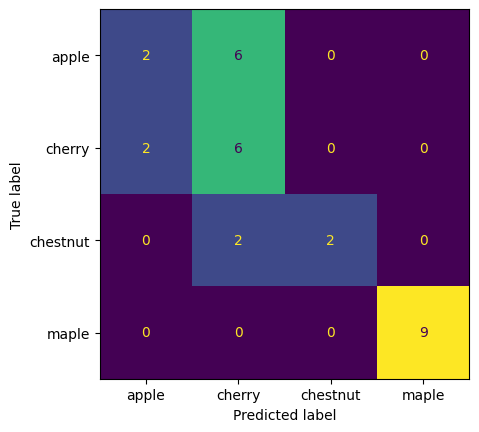

In [25]:
images, labels = next(iter(DataLoader(val_ds, batch_size=len(val_ds))))
with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()
ConfusionMatrixDisplay.from_predictions(labels, predictions, display_labels=train_ds.classes, colorbar=False)
plt.show()

*Which two species are confused most often? Why might that be?*

### 2e. The model as a file

A trained network is just a file of weights. **ONNX** is a format that other
programs can run without PyTorch — among them *ONNX Runtime Web*, which runs
the network inside a web browser, on the phone itself. The class names and
the preprocessing are stored inside the file as metadata, so the file alone
says how it must be fed. (The export needs the `onnx` and `onnxscript`
packages; in Colab the cell installs them.)

In [26]:
if "google.colab" in sys.modules:
    %pip install -q onnx onnxscript
import onnx

model.eval().cpu()
torch.onnx.export(model, (torch.zeros(1, 3, 96, 96),), "leaf_model.onnx",
                  input_names=["image"], output_names=["logits"], external_data=False)

model_info = {"classes": train_ds.classes, "input_size": 96, "mean": mean, "std": std}
onnx_model = onnx.load("leaf_model.onnx")
onnx_model.metadata_props.add(key="model_info", value=json.dumps(model_info))
onnx.save(onnx_model, "leaf_model.onnx")
print(f"leaf_model.onnx: {os.path.getsize('leaf_model.onnx') / 1e6:.1f} MB")

[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
leaf_model.onnx: 6.3 MB


Your page must give the same probabilities as the notebook. The next cell
saves one validation image as `check_image.jpg` with the model's
probabilities in `check_expected.json`, the metadata as `model_info.json`,
and packs the four files for the agent into `ex08_for_agent.zip`. In Colab
the browser downloads the zip; if nothing happens, open the *Files* panel
(the folder icon on the left) and download it from there. Run locally, the
zip is next to the notebook.

In [27]:
Image.open(val_ds.imgs[0][0]).save("check_image.jpg", quality=95)
x = transform(Image.open("check_image.jpg").convert("RGB")).unsqueeze(0)
with torch.no_grad():
    probabilities = model(x).softmax(dim=1)[0]
check_expected = dict(zip(train_ds.classes, probabilities.tolist()))
print(check_expected)
with open("check_expected.json", "w") as f:
    json.dump(check_expected, f, indent=1)
with open("model_info.json", "w") as f:
    json.dump(model_info, f)

with zipfile.ZipFile("ex08_for_agent.zip", "w") as archive:
    for name in ["leaf_model.onnx", "model_info.json", "check_image.jpg", "check_expected.json"]:
        archive.write(name)
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("ex08_for_agent.zip")

{'apple': 0.001426716335117817, 'cherry': 0.9981143474578857, 'chestnut': 4.9615875468589365e-05, 'maple': 0.00040932343108579516}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2f. Your own page, by your agent

<p style="color: #c00000;"><strong>! Compulsory hand-in: complete and submit Task 2 and the report of Task 4 within 48 hours after your lab. Attendance will not be credited unless you complete this requirement.</strong></p>

**The goal.** A web page on GitHub Pages that classifies the **live camera
of your phone** with **your exported model** — opened from a link, nothing to
install, working on Android and iPhone, the network running in the phone's
browser. The camera app of the course shows what such a page can look like;
yours is written by your agent.

Unpack `ex08_for_agent.zip` into an empty folder, start your coding agent
there (check `gh auth status` first) and give it your instructions. A
starting point you may use or adapt:

> In this folder are my leaf classifier leaf_model.onnx and its description model_info.json. Make a web page (one index.html, plain JavaScript, onnxruntime-web from a CDN) that classifies leaves live from the phone's rear camera with this model. Follow model_info.json exactly: crop the central square of the frame, resize it to the input size, scale the RGB pixels to 0–1, standardize each channel with mean/std, input shape 1×3×size×size. Show the probability of every class, updated live. It must work in Safari on iPhone. Add a photo upload as a fallback and check that check_image.jpg gives the probabilities in check_expected.json.
> Then create a public GitHub repository mlr-ex08 with gh, add a README.md with the URL of the page, push it, enable GitHub Pages from the main branch, invite MLRteacher as a collaborator, wait until the page is online and give me its URL. Add a clearly labelled QR code at the bottom of my page that opens its final public GitHub Pages URL on a phone, with a clickable text link next to it. Generate the QR locally or in the browser; do not use an external QR-image service. The QR must point to my own deployed app. Verify the encoded URL matches the live page.

With the CERIT models of lab 5 use the **`agentic`** model: the
`coder` model cannot look at images and stops when it tries. If the agent
stops with a server error, run it again or type *continue* — the files it
has already written stay. While the agent works, go on with Task 3.

**Requirements, and how you check each one in `REVIEW.md`:**

1. **It runs on your phone:** the Pages URL opens on your phone and
   classifies the live camera. → A screenshot from your phone with a leaf
   (or a photo of a leaf on another screen) and the probabilities.
2. **The same numbers as the notebook:** → Upload `check_image.jpg` on the
   page and write its probabilities next to `check_expected.json`. Do they
   agree to three decimals?
3. **The preprocessing matches your model:** → Find in `index.html` where the
   frame is cropped, resized to 96 × 96, divided by 255 and standardized with
   the mean and std, and in which order the channels go into the tensor.
   Does it match `model_info.json` and the `transform` of the notebook?
4. **Nothing leaves the phone:** → Is the image sent anywhere? Which URLs
   does the page load, and why?

For each point write in `REVIEW.md` what you did, what you found and what was
fixed. Do not let the agent write `REVIEW.md`.

**The hand-in:** the **public** repository `mlr-ex08` with `index.html`, the
four files from the ZIP, a `README.md` with the Pages URL, your `REVIEW.md`
with the phone screenshot, your **`REPORT.md` of Task 4**, and **`MLRteacher` invited as a collaborator**
(Settings → Collaborators; a pending invitation is enough), so that the
teacher finds it. What is pushed within **48 hours after your lab** counts.
The repository is public, so everybody can see it — put nothing personal in
it.

<p style="color: #c00000;"><strong>! Plagiarism check: all hand-ins will be checked for plagiarism.</strong></p>

## Task 3 — Your own pipeline

Now write a pipeline yourself on the same data: your own `Dataset` instead
of `ImageFolder`, your own small convolutional network as an `nn.Module`,
trained from scratch, and the training loop. Then add two improvements and
measure what they bring.

### 3a. Your own `Dataset` and `DataLoader`

A `Dataset` is any object with two methods: `__len__`, which says how many
samples there are, and `__getitem__(i)`, which returns the $i$-th sample as a
pair `(input, class index)`. That is the whole interface; `ImageFolder` is
exactly such a class. Write it for our folders: the classes are the sorted
subfolder names, and the files of each class are taken in sorted order (that
is what `ImageFolder` does). Read an image with
`Image.open(path).convert("RGB")` and apply `self.transform` to it.

Then create the two `DataLoader`s with the same settings as in Task 2.

In [28]:
class LeafDataset(Dataset):
    def __init__(self, folder, transform):
        self.transform = transform
        # The class names: the sorted subfolders of the folder.
        # A list of (file path, class index) pairs: every class, its files in sorted order.
        self.classes = sorted(os.listdir(folder))
        self.samples = []
        for class_idx, class_name in enumerate(self.classes):
            class_dir = os.path.join(folder, class_name)
            if os.path.isdir(class_dir):
                for file_name in sorted(os.listdir(class_dir)):
                    self.samples.append((os.path.join(class_dir, file_name), class_idx))

    def __len__(self):
        # The number of samples.
        return len(self.samples)

    def __getitem__(self, i):
        # Open the i-th image as RGB, apply the transform, return it with its class index.
        path, class_idx = self.samples[i]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, class_idx


my_train_ds = LeafDataset("data/leaves/train", transform)
my_val_ds = LeafDataset("data/leaves/val", transform)
# The two loaders: training shuffled, validation not, batches of 32.
my_train_loader = DataLoader(my_train_ds, batch_size=32, shuffle=True)
my_val_loader = DataLoader(my_val_ds, batch_size=32, shuffle=False)

image, label = my_train_ds[-1]
print(my_train_ds.classes, "| train", len(my_train_ds), "| val", len(my_val_ds))
print("the last sample equals ImageFolder's:", torch.equal(image, train_ds[-1][0]) and label == train_ds[-1][1])

['apple', 'cherry', 'chestnut', 'maple'] | train 107 | val 29
the last sample equals ImageFolder's: True


### 3b. Your network as `nn.Module`

`nn.Sequential` (the `classifier` printed in 2b is one) only works for a
chain of layers. The general way, used by
every larger network, is a class that **inherits** from
`nn.Module`, as `SineNet` in 1c, and has two methods:

- `__init__` creates the layers and stores them as attributes
  (`self.conv1 = nn.Conv2d(...)`). It must first call `super().__init__()`,
  which sets up the bookkeeping: every layer stored as an attribute is
  registered, so `parameters()` finds its weights.
- `forward(x)` says what to do with a batch `x`: apply the layers in order.
  The functions without parameters can be called directly
  (`torch.relu`, `x.flatten(1)`).

Write a small convolutional network: four blocks of *convolution
$3 \times 3$ with padding 1 + ReLU + max pooling $2 \times 2$* (16, 32, 64
and 64 channels), which shrink the image $96 \to 48 \to 24 \to 12 \to 6$,
then flatten, a linear layer with 64 neurons + ReLU and the output layer with
4 outputs.

In [29]:
class LeafNet(nn.Module):
    def __init__(self):
        super().__init__()
        # The layers as attributes: the four convolutions, one max pooling, the two linear layers.
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(64 * 6 * 6, 64)
        self.fc2 = nn.Linear(64, 4)

    def forward(self, x):
        # Every block: convolution, ReLU, pooling. Then flatten and the two linear layers.
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.pool(self.relu(self.conv4(x)))
        x = x.flatten(1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)


torch.manual_seed(0)
my_model = LeafNet().to(device)
print("parameters:", sum(p.numel() for p in my_model.parameters()))
print("output for 5 images:", tuple(my_model(torch.zeros(5, 3, 96, 96).to(device)).shape))

parameters: 208292
output for 5 images: (5, 4)


### 3c. Your training loop

Write the training of `my_model` with your loaders: the loss and Adam with
the learning rate $10^{-3}$, 15 epochs, and in every epoch the batch loop
followed by the validation accuracy; print both. Look at 1g and Task 2 only
when you are stuck.

In [30]:
# The loss function and the optimizer.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(my_model.parameters(), lr=1e-3)

# Every epoch: training mode; for every batch move it to the device, zero the gradients,
# forward pass, loss, backward pass, optimizer step, and add up the loss.
# Then evaluation mode and, without gradients, count the correct validation predictions.
# Print the mean training loss and the validation accuracy.
for epoch in range(15):
    my_model.train()
    loss_sum = 0.0
    for images, labels in my_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(my_model(images), labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()

    my_model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in my_val_loader:
            images, labels = images.to(device), labels.to(device)
            correct += (my_model(images).argmax(dim=1) == labels).sum().item()

    print(f"epoch {epoch + 1:2d}  training loss {loss_sum / len(my_train_loader):.4f}  validation accuracy {correct / len(my_val_ds):.3f}")

epoch  1  training loss 1.3814  validation accuracy 0.310
epoch  2  training loss 1.3261  validation accuracy 0.310
epoch  3  training loss 1.2852  validation accuracy 0.310
epoch  4  training loss 1.2399  validation accuracy 0.414
epoch  5  training loss 1.1290  validation accuracy 0.448
epoch  6  training loss 1.0221  validation accuracy 0.552
epoch  7  training loss 0.9118  validation accuracy 0.552
epoch  8  training loss 0.8143  validation accuracy 0.586
epoch  9  training loss 0.7449  validation accuracy 0.655
epoch 10  training loss 0.6194  validation accuracy 0.517
epoch 11  training loss 0.5351  validation accuracy 0.586
epoch 12  training loss 0.5612  validation accuracy 0.448
epoch 13  training loss 0.6771  validation accuracy 0.517
epoch 14  training loss 0.5190  validation accuracy 0.690
epoch 15  training loss 0.3625  validation accuracy 0.552


### 3d. Two improvements

Your network sees the same photographs in every epoch and soon knows
them by heart: the training loss keeps falling, the validation accuracy
stops growing. Two standard remedies:

- **Augmentation:** every time an image is loaded, it is randomly changed —
  a random crop of 60–100 % of the image resized back to 96 × 96
  (`transforms.RandomResizedCrop(96, scale=(0.6, 1.0))`), horizontal and
  vertical flips, a rotation by up to 20° (`RandomRotation(20)`) — and then
  `ToTensor` and `Normalize` as before. The network never sees exactly the
  same image twice, so it has to learn the leaf rather than the photograph.
  Only the training images are augmented; the validation stays as it is.
- **Batch normalization:** `nn.BatchNorm2d(channels)` after every
  convolution standardizes its outputs over the batch and then lets the
  network scale and shift them; training becomes more stable. Copy `LeafNet`
  into `LeafNetBN` and add the four layers.

Then train `LeafNetBN` with the augmented training loader: copy your
training loop from 3c into the last cell below and compare the validation
accuracy with 3c. To see what each improvement brings alone, switch the other
one off and run again.

In [31]:
# The augmented training transform, a training dataset with it and its loader.
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(96, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

aug_train_ds = LeafDataset("data/leaves/train", aug_transform)
aug_train_loader = DataLoader(aug_train_ds, batch_size=32, shuffle=True)

class LeafNetBN(nn.Module):
    # LeafNet with a batch normalization after every convolution, before the ReLU.
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(64 * 6 * 6, 64)
        self.fc2 = nn.Linear(64, 4)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.flatten(1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

In [32]:
torch.manual_seed(0)
my_model_bn = LeafNetBN().to(device)
# Your training loop of 3c, with the augmented training loader.
criterion = nn.CrossEntropyLoss()
optimizer_bn = torch.optim.Adam(my_model_bn.parameters(), lr=1e-3)

for epoch in range(15):
    my_model_bn.train()
    loss_sum = 0.0
    for images, labels in aug_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_bn.zero_grad()
        loss = criterion(my_model_bn(images), labels)
        loss.backward()
        optimizer_bn.step()
        loss_sum += loss.item()

    my_model_bn.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in my_val_loader:
            images, labels = images.to(device), labels.to(device)
            correct += (my_model_bn(images).argmax(dim=1) == labels).sum().item()

    print(f"epoch {epoch + 1:2d}  training loss {loss_sum / len(aug_train_loader):.4f}  validation accuracy {correct / len(my_val_ds):.3f}")

epoch  1  training loss 1.6105  validation accuracy 0.517
epoch  2  training loss 1.0961  validation accuracy 0.276
epoch  3  training loss 1.1374  validation accuracy 0.276
epoch  4  training loss 0.9100  validation accuracy 0.552
epoch  5  training loss 0.7795  validation accuracy 0.448
epoch  6  training loss 0.8278  validation accuracy 0.414
epoch  7  training loss 0.7081  validation accuracy 0.414
epoch  8  training loss 0.7317  validation accuracy 0.517
epoch  9  training loss 0.6490  validation accuracy 0.552
epoch 10  training loss 0.5933  validation accuracy 0.517
epoch 11  training loss 0.5824  validation accuracy 0.621
epoch 12  training loss 0.5987  validation accuracy 0.655
epoch 13  training loss 0.5485  validation accuracy 0.724
epoch 14  training loss 0.5979  validation accuracy 0.621
epoch 15  training loss 0.5794  validation accuracy 0.690


*What did the two improvements bring? Is the difference larger than the
noise — how much accuracy is one validation image worth?*

## Task 4 — A better classifier (with an agent)

**The goal.** Make the leaf classifier as good as you can **on the phone
camera**, and find out with your agent what each change brings. You decide
what to try and judge the results; the agent writes the code. Write your own
instructions for it.

<p style="color: #c00000;"><strong>! Put this into your instructions, in these words or stronger: keep our simple, readable code. The agent starts from your Task 3 pipeline and adds or changes only what a variant needs — no rewrite, no new framework, classes or helper layers that are not necessary, no "improvements" nobody asked for. You must be able to read every change and explain it in your report.</strong></p>

Candidates — try as many as you can:

- **colour augmentation** (`transforms.ColorJitter`) next to the geometric one;
- **transfer learning** as in Task 2: the pretrained network with only the
  new last layer trained (the rest frozen), against the whole network
  fine-tuned;
- the pretrained network **with augmentation and a learning-rate scheduler**
  (for example cosine, `torch.optim.lr_scheduler.CosineAnnealingLR`) and more
  epochs;
- **dropout**, **global average pooling** instead of flattening, **AdamW**
  with weight decay, **label smoothing**, keeping the weights of the **best
  epoch**;
- **last years' photographs** — an optional, separate historical dataset
  ([archive ZIP](https://raw.githubusercontent.com/tomasvicar/MLR-public/master/exercises/data/ex08_leaves_images.zip), the same `train` / `val` layout,
  175 + 30 per species, other students, other phones): more training data —
  does adding them help? — and a test on leaves nobody of your group
  photographed;
- anything else you find.

**Requirements:**

1. **A fair comparison:** a fixed baseline (your Task 3 network or the Task 2
   model), then **one change at a time** against it, then the best
   combinations; every variant trained on the same training images with a
   fixed seed. Repeat the important rows with two or three seeds — one run
   on a small validation set is noisy.
2. **Closer to the camera:** besides the validation accuracy, measure every
   variant on a *camera-like* validation set — the validation images
   randomly cropped, rotated and with changed colours, generated once with a
   fixed seed — or on last years' photographs.
3. **A short report `REPORT.md`, written by you — part of the compulsory
   hand-in:** the table, what each change brought, whether the difference is
   larger than the noise, what did *not* help, and which model you would put
   on the phone. Try that one in the course camera app (export it as in 2e).
   Push `REPORT.md` into your `mlr-ex08` repository next to `REVIEW.md`
   within **48 hours after your lab**.

<p style="color: #c00000;"><strong>! Compulsory hand-in: complete and submit Task 2 and the report of Task 4 within 48 hours after your lab. Attendance will not be credited unless you complete this requirement.</strong></p>

In [33]:
# Task 4a: Camera-like validation set & Last years' historical dataset
urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/tomasvicar/MLR-public/master/exercises/data/ex08_leaves_images.zip",
    "data/hist.zip"
)
os.makedirs("data/historical", exist_ok=True)
with zipfile.ZipFile("data/hist.zip") as zf:
    zf.extractall("data/historical")

color_aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(96, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Fixed camera-like validation set (3 perturbed views per validation image, seed=42)
torch.manual_seed(42)
cam_raw_ds = LeafDataset("data/leaves/val", color_aug_transform)
cam_imgs, cam_labels = [], []
for _ in range(3):
    for img, lbl in cam_raw_ds:
        cam_imgs.append(img)
        cam_labels.append(lbl)
cam_val_ds = TensorDataset(torch.stack(cam_imgs), torch.tensor(cam_labels))
cam_val_loader = DataLoader(cam_val_ds, batch_size=32, shuffle=False)

hist_train_ds = LeafDataset("data/historical/leaves/train", color_aug_transform)
hist_val_ds = LeafDataset("data/historical/leaves/val", transform)
hist_val_loader = DataLoader(hist_val_ds, batch_size=64, shuffle=False)
print(f"Camera-like val: {len(cam_val_ds)} | Historical train: {len(hist_train_ds)} | Historical val: {len(hist_val_ds)}")


Camera-like val: 87 | Historical train: 700 | Historical val: 120


In [34]:
# Task 4b: Comparing Task 3 Scratch CNN variants and 5 Pretrained Architectures (seeds 0, 1, 2)
def evaluate_loader(net, loader, total):
    net.eval()
    correct = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (net(xb).argmax(dim=1) == yb).sum().item()
    return correct / total

def build_pretrained_model(arch, freeze_backbone=False, dropout=0.3):
    if arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights="DEFAULT")
        if freeze_backbone:
            for p in m.parameters(): p.requires_grad = False
        m.classifier[2] = nn.Dropout(p=dropout, inplace=True)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 4)
    elif arch == "mobilenet_v3_large":
        m = models.mobilenet_v3_large(weights="DEFAULT")
        m.classifier[2] = nn.Dropout(p=dropout, inplace=True)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 4)
    elif arch == "shufflenet_v2_x1_0":
        m = models.shufflenet_v2_x1_0(weights="DEFAULT")
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, 4))
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights="DEFAULT")
        m.classifier = nn.Sequential(nn.Dropout(p=dropout, inplace=True), nn.Linear(m.classifier[1].in_features, 4))
    elif arch == "resnet18":
        m = models.resnet18(weights="DEFAULT")
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, 4))
    return m.to(device)


A1. LeafNet Baseline (Task 3c)                       | Val:  62.1± 2.8% | CamVal:  40.6± 2.9% | HistVal:  36.7± 2.7%
A2. LeafNet + BatchNorm only (LeafNetBN)             | Val:  70.1± 3.3% | CamVal:  40.2± 2.8% | HistVal:  39.4± 2.1%
A3. LeafNet + Geom Augmentation only                 | Val:  57.5± 4.3% | CamVal:  47.5± 2.9% | HistVal:  38.3± 1.8%
A4. LeafNetBN + Geom Augmentation (Task 3d)          | Val:  54.0± 5.9% | CamVal:  44.8± 1.6% | HistVal:  39.2± 3.5%
A5. LeafNetBN + Geom + ColorJitter                   | Val:  65.5± 2.8% | CamVal:  59.4± 3.8% | HistVal:  42.5± 3.8%
A6. LeafNetBN + Full Aug + Best Epoch                | Val:  74.7± 4.3% | CamVal:  57.5± 3.3% | HistVal:  44.2± 3.1%
A7. LeafNetBN + Dropout(0.3) + Full Aug + Best       | Val:  71.3± 4.3% | CamVal:  58.2± 4.8% | HistVal:  42.5± 2.4%
A8. LeafNetGAP (GAP + Dropout 0.3) + Full Aug        | Val:  65.5± 5.6% | CamVal:  56.3± 2.5% | HistVal:  36.9± 0.4%
A9. LeafNetBN + AdamW + Smooth(0.1) + Cosine(25ep)   | Val:  71.

In [35]:
# Task 4c: Export winning EfficientNet-B0 model to ONNX for the phone app
torch.manual_seed(2)
full_train_ds = LeafDataset("data/leaves/train", color_aug_transform)
full_train_loader = DataLoader(full_train_ds, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(2))

best_model = build_pretrained_model("efficientnet_b0", dropout=0.2)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(best_model.parameters(), lr=6e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

best_val, best_state = -1.0, None
for epoch in range(20):
    best_model.train()
    for images, labels in full_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(best_model(images), labels)
        loss.backward()
        optimizer.step()
    scheduler.step()
    val_acc = evaluate_loader(best_model, my_val_loader, len(my_val_ds))
    if val_acc >= best_val:
        best_val = val_acc
        best_state = copy.deepcopy(best_model.state_dict())

best_model.load_state_dict(best_state)
best_model.eval().cpu()
torch.onnx.export(best_model, (torch.zeros(1, 3, 96, 96),), "best_leaf_model.onnx",
                  input_names=["image"], output_names=["logits"], external_data=False)
onnx_m = onnx.load("best_leaf_model.onnx")
onnx_m.metadata_props.add(key="model_info", value=json.dumps(model_info))
onnx.save(onnx_m, "best_leaf_model.onnx")
print(f"Exported best_leaf_model.onnx (Val Acc: {best_val:.3f})")


Exported best_leaf_model.onnx (Val Acc: 0.897)


## Summary

* A batch puts the samples in the rows; its loss is the mean over the
  samples, its gradient the mean of their gradients. The layers compute in
  `float32`, and the model and every batch must be on the same device.
* A `Dataset` is `__len__` + `__getitem__`; a `DataLoader` shuffles it and
  stacks the samples into batches. `ImageFolder` is a ready-made `Dataset`
  for one folder per class.
* A network is a class inheriting from `nn.Module`: `__init__` creates the
  layers as attributes (after `super().__init__()`), `forward` applies them.
* The training loop is always the same — `zero_grad()`, forward, loss,
  `backward()`, `step()` — with `model.train()` / `model.eval()` and
  `torch.no_grad()` for the validation; `state_dict()` holds everything the
  network has learned.
* With a few dozen photographs per class, a network pretrained on ImageNet beats a
  network trained from scratch; augmentation and batch normalization help
  the one from scratch.
* An improvement is measured one change at a time, on the same validation
  images, against a fixed baseline.
* A trained network is a file. Exported to ONNX, together with its classes
  and preprocessing, it runs without PyTorch — even in a phone's browser.

Next time: one network, many heads — classification, segmentation and
denoising of images and signals — and one of them built with an agent.